
PARÂMETROS INICIAIS
phi_1a = 3.146587 rad
phi_1b = 0.790367 rad
phi_2a = 4.961796 rad
phi_2b = 0.871097 rad
G_SOA  = 4.000000


C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_20552\3977210902.py:220: RuntimeWarning: overflow encountered in scalar multiply
  da_dt = (-(1j * delta_omega+ gamma)* a_cav- 1j* eta_fc* Nc* a_cav- 1j* mu* np.sqrt(Pin))
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_20552\3977210902.py:221: RuntimeWarning: overflow encountered in scalar power
  dNc_dt = (-Nc / tau+ xi* intensity**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_20552\3977210902.py:221: RuntimeWarning: overflow encountered in scalar multiply
  dNc_dt = (-Nc / tau+ xi* intensity**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_20552\3977210902.py:217: RuntimeWarning: overflow encountered in scalar power
  intensity = ( np.abs(a_cav)**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_20552\3977210902.py:221: RuntimeWarning: invalid value encountered in scalar add
  dNc_dt = (-Nc / tau+ xi* intensity**2)


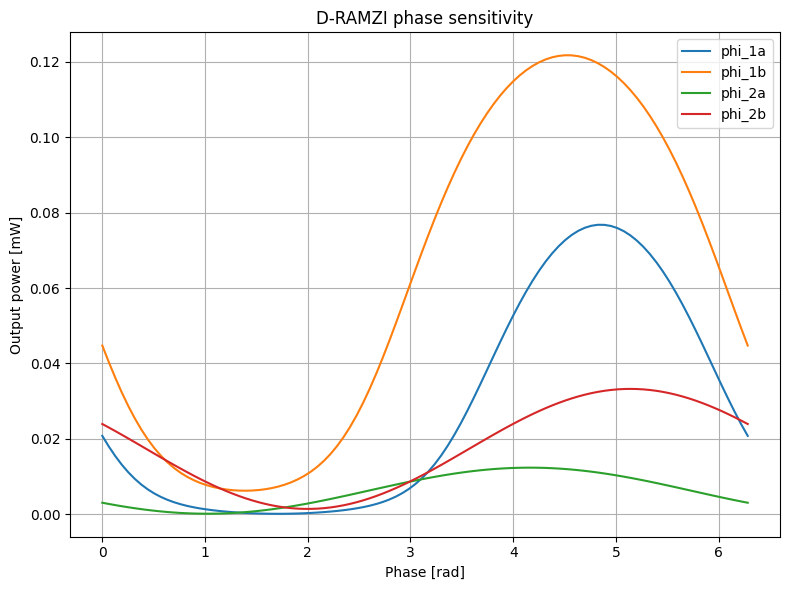

C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_20552\3977210902.py:220: RuntimeWarning: invalid value encountered in scalar multiply
  da_dt = (-(1j * delta_omega+ gamma)* a_cav- 1j* eta_fc* Nc* a_cav- 1j* mu* np.sqrt(Pin))


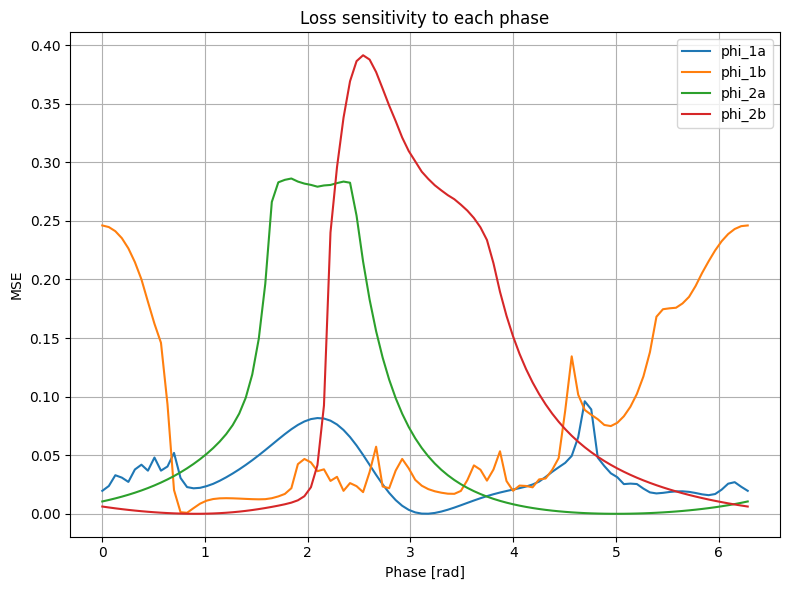


TREINAMENTO

Epoch 001 | Loss = 3.369554e-05 | |grad| = 6.421e-03
    gradients = [-1.568e-04, -6.366e-03, -5.236e-04, -6.311e-04, -5.725e-05]
Epoch 002 | Loss = 3.004871e-05 | |grad| = 4.968e-03
    gradients = [-4.130e-04, -4.906e-03, -4.189e-04, -5.044e-04, -6.387e-05]
Epoch 003 | Loss = 2.785553e-05 | |grad| = 3.891e-03
    gradients = [-6.050e-04, -3.807e-03, -3.394e-04, -4.082e-04, -6.889e-05]
Epoch 004 | Loss = 2.650148e-05 | |grad| = 3.097e-03
    gradients = [-7.484e-04, -2.973e-03, -2.787e-04, -3.348e-04, -7.264e-05]
Epoch 005 | Loss = 2.563679e-05 | |grad| = 2.516e-03
    gradients = [-8.550e-04, -2.337e-03, -2.322e-04, -2.785e-04, -7.538e-05]
Epoch 006 | Loss = 2.506007e-05 | |grad| = 2.097e-03
    gradients = [-9.334e-04, -1.851e-03, -1.964e-04, -2.353e-04, -7.733e-05]
Epoch 007 | Loss = 2.465433e-05 | |grad| = 1.800e-03
    gradients = [-9.903e-04, -1.478e-03, -1.689e-04, -2.020e-04, -7.867e-05]
Epoch 008 | Loss = 2.435112e-05 | |grad| = 1.594e-03
    gradients = [-1.031

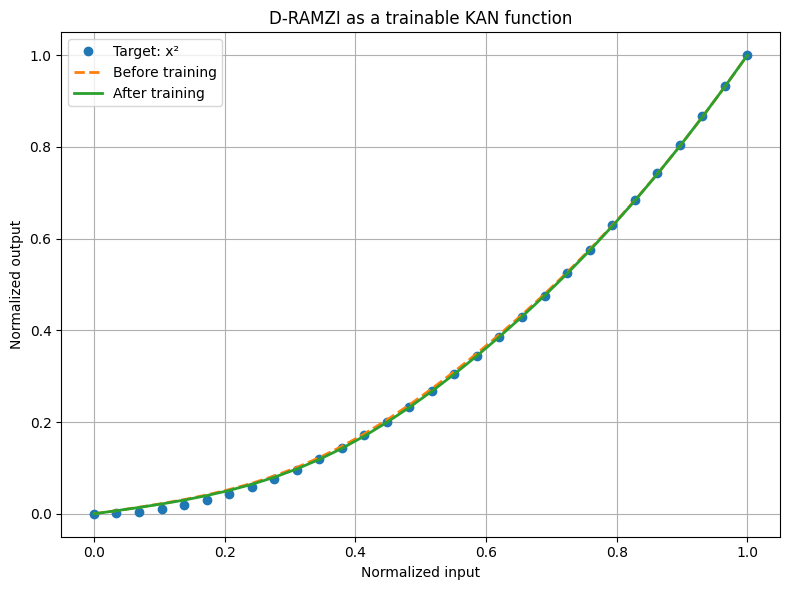

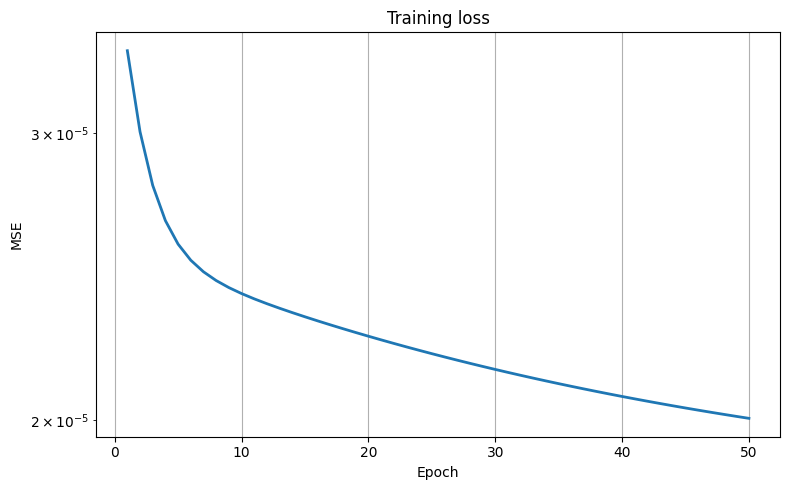

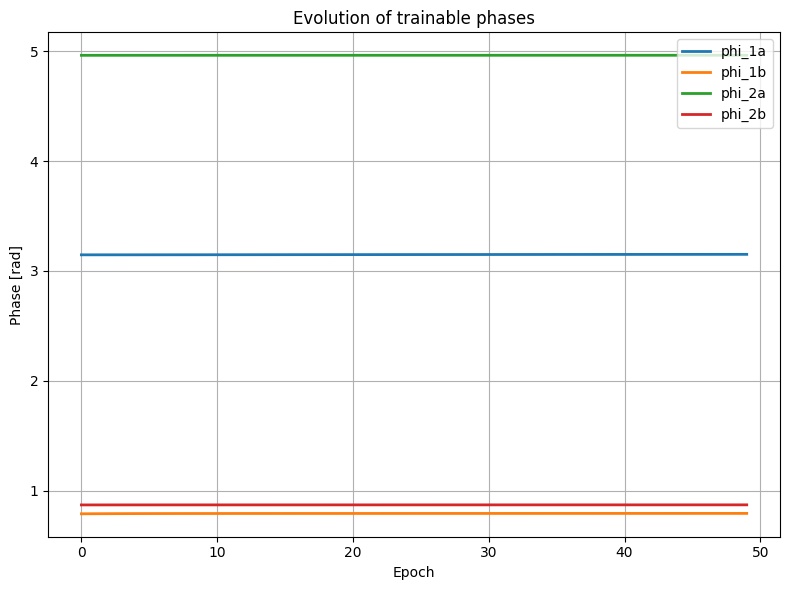

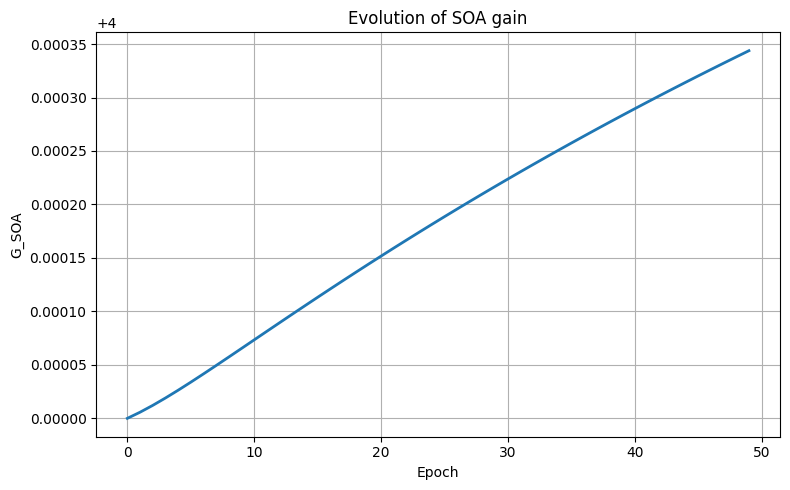

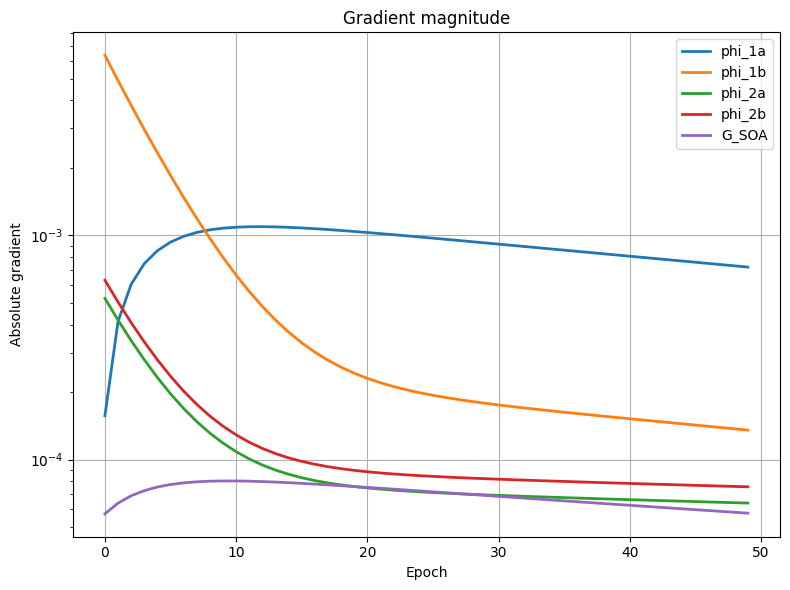


Calculando mapa de loss...


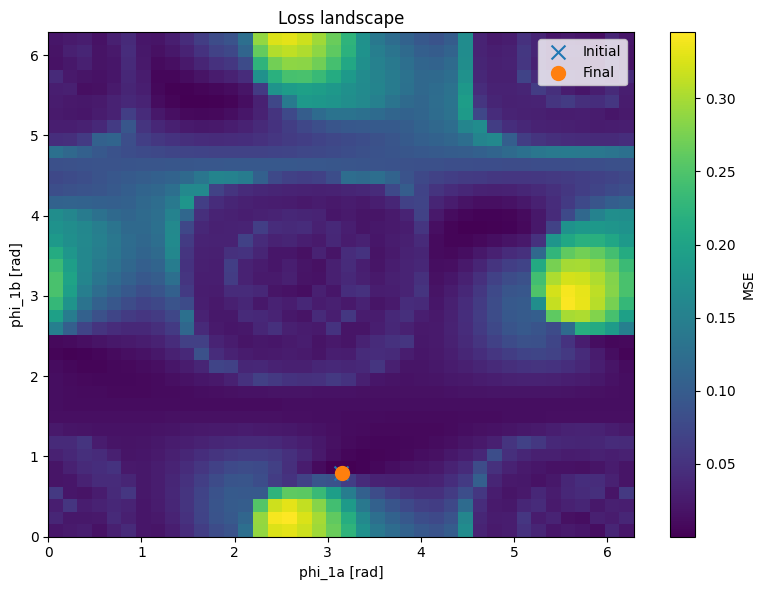

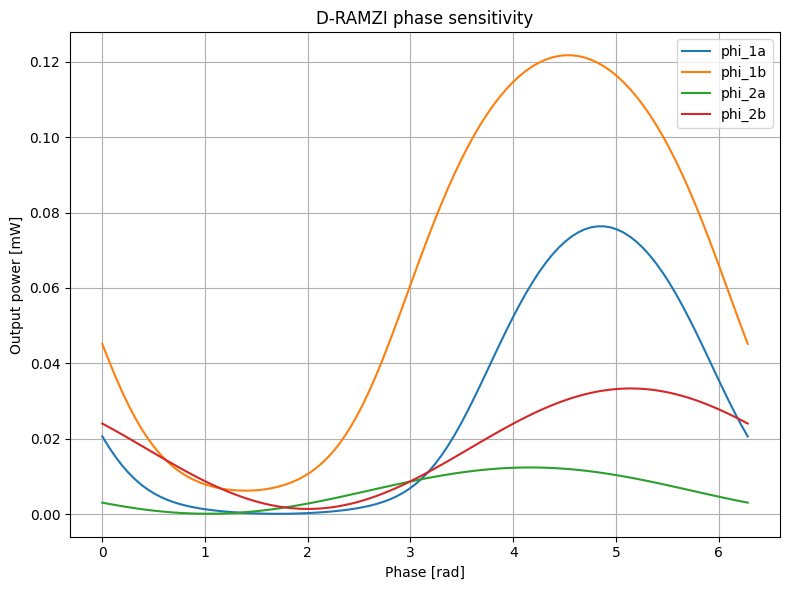

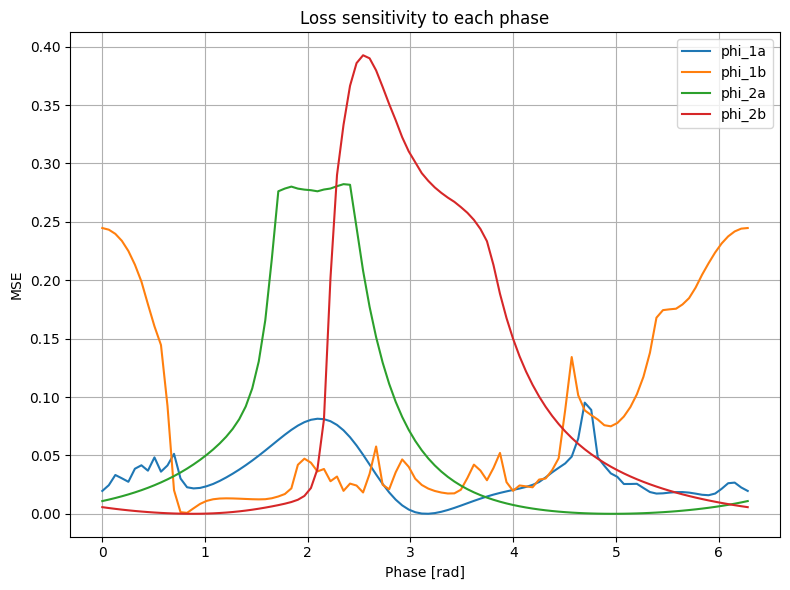

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from scipy.integrate import solve_ivp


# ============================================================
# ============================================================
# 1. PARÂMETROS FÍSICOS
# ============================================================
# ============================================================

lambda0 = 1550e-9

neff0 = 2.3537
ng = 2.3537


# ------------------------------------------------------------
# Geometria
# ------------------------------------------------------------

FSR_nm = 20e-9

L = lambda0**2 / (ng * FSR_nm)

L_rr_1 = L * 2
L_rr_2 = L * 2

L_wvg1 = L * 4
L_wvg2 = 50e-6 + L * 2
L_wvg3 = 50e-6

L_wvg4 = L * 4
L_wvg5 = 50e-6
L_wvg6 = 50e-6 + L * 2


# ------------------------------------------------------------
# Parâmetros dos MRRs
# ------------------------------------------------------------

alpha1 = 0.80
alpha2 = 0.80


# ------------------------------------------------------------
# Dinâmica de portadores
# ------------------------------------------------------------

eta_fc = 1e-6
gamma = 1e10
mu = 1e5
tau = 5e-9
xi = 1e40


# ------------------------------------------------------------
# Detuning
# ------------------------------------------------------------

delta_f = 2e9

delta_omega = 2 * np.pi * delta_f


# ============================================================
# ============================================================
# 2. FUNÇÕES ÓPTICAS
# ============================================================
# ============================================================

def Beta_calc(
    ng,
    neff0,
    lambda0,
    lamb_vector
):

    dneff_dlambda = (
        neff0 - ng
    ) / lambda0

    neff = (
        neff0
        + dneff_dlambda
        * (lamb_vector - lambda0)
    )

    beta = (
        2 * np.pi
        * neff
        / lamb_vector
    )

    return beta


# ============================================================

def Beta_MRR(
    ng,
    neff0,
    lambda0,
    lamb_vector,
    Nc,
    eta_fc
):

    dneff_dlambda = (
        neff0 - ng
    ) / lambda0

    neff = (
        neff0
        + dneff_dlambda
        * (lamb_vector - lambda0)
        - eta_fc * Nc
    )

    beta = (
        2 * np.pi
        * neff
        / lamb_vector
    )

    return beta


# ============================================================

def DC(r):

    t = np.sqrt(1 - r**2)

    C = np.array([[r,-1j * t],
                  [-1j * np.conj(t),np.conj(r)]])

    return C


# ============================================================

def MRR(
    beta,
    L,
    a,
    r
):

    H = np.zeros((len(beta),1,1),dtype=complex)

    H[:, 0, 0] = (np.conj(r)- a* np.exp(-1j* beta* L)) / (1- r* a* np.exp(-1j* beta* L))

    return H


# ============================================================

def WVG(
    beta,
    L
):

    H = np.zeros((len(beta),1,1),dtype=complex)

    H[:, 0, 0] = np.exp(-1j* beta* L)

    return H


# ============================================================

def PHASE(phi):

    return np.array([[1,0],
                     [0,np.exp(1j * phi)]
    ], dtype=complex)


# ============================================================
# ============================================================
# 3. MATRIZES FIXAS
# ============================================================
# ============================================================

C = DC(
    1 / np.sqrt(2)
)


Y_splitter = np.array([
    [1 / np.sqrt(2)],
    [1 / np.sqrt(2)]
])


# ============================================================
# ============================================================
# 4. DINÂMICA DOS PORTADORES
# ============================================================
# ============================================================

def carrier_dynamics(
    t,
    y,
    Pin,
    delta_omega
):

    a_real = y[0]
    a_imag = y[1]
    Nc = y[2]

    a_cav = (a_real+ 1j * a_imag)

    intensity = ( np.abs(a_cav)**2)


    da_dt = (-(1j * delta_omega+ gamma)* a_cav- 1j* eta_fc* Nc* a_cav- 1j* mu* np.sqrt(Pin))
    dNc_dt = (-Nc / tau+ xi* intensity**2)


    return [da_dt.real,da_dt.imag,dNc_dt]


# ============================================================

def get_Nc_ss(
    Pin,
    delta_omega
):

    # Evita integração desnecessária em Pin = 0

    if Pin <= 0:

        return 0.0


    sol = solve_ivp(

        lambda t, y:

            carrier_dynamics(t,y,Pin,delta_omega),(0,100e-9),[0.0,0.0,0.0],rtol=1e-9,atol=[1e-20,1e-20,1e-14],method="DOP853")


    return sol.y[2,-1]


# ============================================================
# ============================================================
# 5. MODELO D-RAMZI
# ============================================================
# ============================================================

def D_RAMZI(Pin,vec_lamb,alpha1,phi_1a,phi_1b,alpha2,phi_2a,phi_2b,G_SOA,delta_omega1,delta_omega2):


    # ========================================================
    # Entrada
    # ========================================================

    Ein = np.array([[np.sqrt(Pin)]], dtype=complex)


    # ========================================================
    # Beta das waveguides
    # ========================================================

    beta_wvg = Beta_calc(ng,neff0,lambda0,vec_lamb)


    # ========================================================
    # ========================================================
    # RAMZI 1
    # ========================================================
    # ========================================================


    # --------------------------------------------------------
    # Portadores
    # --------------------------------------------------------

    Nc1 = get_Nc_ss(Pin,delta_omega1)


    # --------------------------------------------------------
    # Beta do ring
    # --------------------------------------------------------

    beta_ring1 = Beta_MRR(ng,neff0,lambda0,vec_lamb,Nc1,eta_fc)


    # --------------------------------------------------------
    # MRR
    # --------------------------------------------------------

    mrr1 = MRR(beta_ring1,L=L_rr_1,a=alpha1,r=1 / np.sqrt(2))


    # --------------------------------------------------------
    # Waveguides
    # --------------------------------------------------------

    wvg1 = WVG(beta_wvg,L_wvg1)

    wvg2 = WVG(beta_wvg,L_wvg2)

    wvg3 = WVG(beta_wvg,L_wvg3)


    # --------------------------------------------------------
    # RAMZI 1
    # --------------------------------------------------------

    RAMZI1 = np.zeros((len(vec_lamb),2, 2),dtype=complex)

    RAMZI1[:, 0, 0] = (mrr1[:, 0, 0])
    RAMZI1[:, 1, 1] = (wvg1[:, 0, 0])

    # --------------------------------------------------------
    # MZI 1
    # --------------------------------------------------------

    MZI1 = np.zeros((len(vec_lamb),2,2),dtype=complex)

    MZI1[:, 0, 0] = (wvg2[:, 0, 0])
    MZI1[:, 1, 1] = (wvg3[:, 0, 0])


    # --------------------------------------------------------
    # Phase shifters
    # --------------------------------------------------------

    Phase_1a = PHASE(phi_1a)

    Phase_1b = PHASE(phi_1b)


    # --------------------------------------------------------
    # Propagação
    # --------------------------------------------------------

    out1 = (Phase_1b@ MZI1@ C@ Phase_1a@ RAMZI1@ Y_splitter@ Ein)


    # --------------------------------------------------------
    # Combinação das duas portas
    # --------------------------------------------------------

    E1 = (out1[:, 0, 0] / np.sqrt(2)+out1[:, 1, 0]/ np.sqrt(2))

    # ========================================================
    # SOA
    # ========================================================

    E2 = (np.sqrt(G_SOA)* E1)


    # ========================================================
    # Potência entrando no segundo RAMZI
    # ========================================================

    Pin2 = (np.abs(E2)**2)


    # Para o treinamento atual vec_lamb contém somente lambda0.
    # Portanto Pin2 possui somente um elemento.

    Pin2_scalar = float(Pin2[0])


    # ========================================================
    # ========================================================
    # RAMZI 2
    # ========================================================
    # ========================================================


    # --------------------------------------------------------
    # Portadores
    # --------------------------------------------------------

    Nc2 = get_Nc_ss(Pin2_scalar,delta_omega2)


    # --------------------------------------------------------
    # Beta do ring
    # --------------------------------------------------------

    beta_ring2 = Beta_MRR(ng,neff0,lambda0,vec_lamb,Nc2,eta_fc)


    # --------------------------------------------------------
    # MRR
    # --------------------------------------------------------

    mrr2 = MRR(beta_ring2,L=L_rr_2,a=alpha2,r=1 / np.sqrt(2))


    # --------------------------------------------------------
    # Waveguides
    # --------------------------------------------------------

    wvg4 = WVG(beta_wvg,L_wvg4)
    wvg5 = WVG(beta_wvg,L_wvg5)
    wvg6 = WVG(beta_wvg,L_wvg6)


    # --------------------------------------------------------
    # RAMZI 2
    # --------------------------------------------------------

    RAMZI2 = np.zeros( (len(vec_lamb),2,2),dtype=complex)
    RAMZI2[:, 0, 0] = (mrr2[:, 0, 0])
    RAMZI2[:, 1, 1] = (wvg4[:, 0, 0])


    # --------------------------------------------------------
    # MZI 2
    # --------------------------------------------------------

    MZI2 = np.zeros((len(vec_lamb),2,2),dtype=complex)
    MZI2[:, 0, 0] = (wvg5[:, 0, 0])
    MZI2[:, 1, 1] = (wvg6[:, 0, 0])


    # --------------------------------------------------------
    # Phase shifters
    # --------------------------------------------------------

    Phase_2a = PHASE(phi_2a)
    Phase_2b = PHASE(phi_2b)


    # --------------------------------------------------------
    # Entrada
    # --------------------------------------------------------

    In2 = E2[:,None,None]


    # --------------------------------------------------------
    # Propagação
    # --------------------------------------------------------

    out2 = (Phase_2b@ MZI2@ C@ Phase_2a@ RAMZI2@ Y_splitter@ In2)


    # --------------------------------------------------------
    # Campo de saída
    # --------------------------------------------------------

    Eout = (out2[:, 0, 0]/ np.sqrt(2)+out2[:, 1, 0]/ np.sqrt(2))


    # --------------------------------------------------------
    # Potência
    # --------------------------------------------------------

    Pout = (np.abs(Eout)**2)


    return Pout


# ============================================================
# ============================================================
# 6. FUNÇÃO ESCALAR DA UNIDADE KAN
# ============================================================
# ============================================================

def photonic_function(x,theta,P_max):

    phi_1a = theta[0]
    phi_1b = theta[1]

    phi_2a = theta[2]
    phi_2b = theta[3]

    G_SOA = theta[4]
    y = np.zeros_like(x,dtype=float)
    
    for i, ix in enumerate(x):
        Pin = (ix* P_max)
        Pout = D_RAMZI(Pin=Pin,vec_lamb=np.array([lambda0]),alpha1=alpha1,phi_1a=phi_1a,phi_1b=phi_1b,alpha2=alpha2,phi_2a=phi_2a,phi_2b=phi_2b,G_SOA=G_SOA,delta_omega1=delta_omega,delta_omega2=delta_omega)
        y[i] = Pout[0]


    return y


# ============================================================
# ============================================================
# 7. NORMALIZAÇÃO
# ============================================================
# ============================================================

def normalize_output(y):

    ymax = np.max(np.abs(y))

    if ymax < 1e-30:
        return y.copy()
    return (y / ymax)


# ============================================================
# ============================================================
# 8. DATASET
# ============================================================
# ============================================================

N_train = 30

x_train = np.linspace(0,1,N_train)


# ------------------------------------------------------------
# Função alvo
#
# Primeira função KAN que queremos representar
# ------------------------------------------------------------

y_train = (x_train**2)


# ============================================================
# ============================================================
# 9. POTÊNCIA
# ============================================================
# ============================================================

P_max = (0.2e-3)


# ============================================================
# ============================================================
# 10. LIMITES
# ============================================================
# ============================================================

theta_min = np.array([0.0,0.0,0.0,0.0,1.0])


theta_max = np.array([2 * np.pi,2 * np.pi,2 * np.pi,2 * np.pi,20.0])


# ============================================================
# ============================================================
# 11. FUNÇÃO DE CUSTO
# ============================================================
# ============================================================

def loss_function(theta):


    y_pred = photonic_function(x_train,theta,P_max)
    y_pred = normalize_output(y_pred)
    error = (y_pred- y_train)

    mse = np.mean(error**2)

    return mse


# ============================================================
# ============================================================
# 12. GRADIENTE NUMÉRICO
# ============================================================
# ============================================================

def numerical_gradient(theta,epsilon):

    gradient = np.zeros_like(theta)


    for i in range(len(theta)):

        theta_plus = (theta.copy())

        theta_minus = (theta.copy())


        theta_plus[i] += (epsilon[i])

        theta_minus[i] -= (epsilon[i])


        # ----------------------------------------------------
        # Limites
        # ----------------------------------------------------

        theta_plus = np.clip(theta_plus,theta_min,theta_max)
        theta_minus = np.clip(theta_minus,theta_min,theta_max)


        # ----------------------------------------------------
        # Loss
        # ----------------------------------------------------

        loss_plus = loss_function(theta_plus)

        loss_minus = loss_function(theta_minus)


        denominator = (theta_plus[i]- theta_minus[i])


        if abs(denominator) > 1e-15:
            gradient[i] = (loss_plus - loss_minus) / denominator

        else:
            gradient[i] = 0.0


    return gradient


# ============================================================
# ============================================================
# 13. TESTE DE SENSIBILIDADE DOS PHASE SHIFTERS
# ============================================================
# ============================================================

def phase_sensitivity_test(theta_reference,Pin_test,N_points=100):


    phase_names = ["phi_1a","phi_1b","phi_2a","phi_2b"]


    phase_vector = np.linspace(0,2 * np.pi,N_points)


    plt.figure(figsize=(8, 6))


    for parameter_index in range(4):


        P_vector = []


        for phi in phase_vector:
            theta_test = (theta_reference.copy())
            theta_test[parameter_index] = phi
            Pout = D_RAMZI(Pin=Pin_test,vec_lamb=np.array([lambda0]),alpha1=alpha1,phi_1a=theta_test[0],phi_1b=theta_test[1],alpha2=alpha2,phi_2a=theta_test[2],phi_2b=theta_test[3],G_SOA=theta_test[4],delta_omega1=delta_omega,delta_omega2=delta_omega)
            P_vector.append(Pout[0])


        P_vector = np.array(P_vector)


        plt.plot(phase_vector,P_vector / 1e-3,label=phase_names[parameter_index])
    plt.xlabel("Phase [rad]")
    plt.ylabel("Output power [mW]")
    plt.title("D-RAMZI phase sensitivity")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


# ============================================================
# ============================================================
# 14. LOSS EM FUNÇÃO DE CADA PHASE
# ============================================================
# ============================================================

def phase_loss_test(theta_reference,N_points=100):


    phase_names = ["phi_1a","phi_1b","phi_2a","phi_2b"]
    phase_vector = np.linspace(0,2 * np.pi,N_points)
    plt.figure(figsize=(8, 6))


    for parameter_index in range(4):
        losses = []
        for phi in phase_vector:
            theta_test = (theta_reference.copy())
            theta_test[parameter_index] = phi
            losses.append(loss_function(theta_test))
        plt.plot(phase_vector,losses,label=phase_names[parameter_index])


    plt.xlabel("Phase [rad]")
    plt.ylabel("MSE")
    plt.title("Loss sensitivity to each phase")
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.show()


# ============================================================
# ============================================================
# 15. INICIALIZAÇÃO
# ============================================================
# ============================================================

# IMPORTANTE:
#
# Não começamos em:
#
# [0, 0, 0, 0]
#
# porque esse ponto pode ser um ponto de simetria da
# resposta interferométrica.


rng = np.random.default_rng(42)
theta = np.array([3.146587,0.790367,4.961796,0.871097,4.0])


theta_initial = (theta.copy())


print("\n==============================")
print("PARÂMETROS INICIAIS")
print("==============================")
print(f"phi_1a = {theta[0]:.6f} rad")
print(f"phi_1b = {theta[1]:.6f} rad")
print(f"phi_2a = {theta[2]:.6f} rad")
print(f"phi_2b = {theta[3]:.6f} rad")
print(f"G_SOA  = {theta[4]:.6f}")


# ============================================================
# ============================================================
# 16. TESTE ANTES DO TREINAMENTO
# ============================================================
# ============================================================

Pin_test = (0.1e-3)


phase_sensitivity_test(theta_initial,Pin_test)


phase_loss_test(theta_initial)


# ============================================================
# ============================================================
# 17. CONFIGURAÇÃO DO TREINAMENTO
# ============================================================
# ============================================================

learning_rate = (0.1)


epochs = (50)


epsilon = np.array([1e-3,1e-3,1e-3,1e-3,1e-3])


# ============================================================
# Históricos
# ============================================================

loss_history = []
theta_history = []
gradient_history = []


# ============================================================
# ============================================================
# 18. LOOP DE TREINAMENTO
# ============================================================
# ============================================================

print("\n==============================")
print("TREINAMENTO")
print("==============================\n")


for epoch in range(epochs):


    # --------------------------------------------------------
    # Loss
    # --------------------------------------------------------

    loss = loss_function(theta)


    # --------------------------------------------------------
    # Gradiente
    # --------------------------------------------------------

    gradient = numerical_gradient(theta,epsilon)


    # --------------------------------------------------------
    # Histórico
    # --------------------------------------------------------

    loss_history.append(loss)
    theta_history.append(theta.copy())
    gradient_history.append(gradient.copy())


    # --------------------------------------------------------
    # Impressão
    # --------------------------------------------------------

    print(f"Epoch {epoch + 1:03d} | "f"Loss = {loss:.6e} | "f"|grad| = "f"{np.linalg.norm(gradient):.3e}")
    print("    gradients = ["f"{gradient[0]:+.3e}, "f"{gradient[1]:+.3e}, "f"{gradient[2]:+.3e}, "f"{gradient[3]:+.3e}, "f"{gradient[4]:+.3e}""]")


    # --------------------------------------------------------
    # Gradient descent
    # --------------------------------------------------------
    theta = (theta- learning_rate* gradient)
    # --------------------------------------------------------
    # Limites
    # --------------------------------------------------------

    theta = np.clip(theta,theta_min,theta_max)


# ============================================================
# Converter históricos
# ============================================================

theta_history = np.array(theta_history)
gradient_history = np.array(gradient_history)


# ============================================================
# ============================================================
# 19. RESULTADOS
# ============================================================
# ============================================================

print("\n==============================")
print("PARÂMETROS TREINADOS")
print("==============================")
print(f"phi_1a = {theta[0]:.6f} rad")
print(f"phi_1b = {theta[1]:.6f} rad")
print(f"phi_2a = {theta[2]:.6f} rad")
print(f"phi_2b = {theta[3]:.6f} rad")
print(f"G_SOA  = {theta[4]:.6f}")
print("\nLoss final = "f"{loss_function(theta):.8e}")


# ============================================================
# ============================================================
# 20. RESPOSTA ANTES E DEPOIS
# ============================================================
# ============================================================

y_initial = photonic_function(x_train,theta_initial,P_max)
y_initial = normalize_output(y_initial)
y_final = photonic_function(x_train,theta,P_max)
y_final = normalize_output(y_final)


# ============================================================
# ============================================================
# 21. GRÁFICO DA APROXIMAÇÃO
# ============================================================
# ============================================================

plt.figure(figsize=(8, 6))
plt.plot(x_train,y_train,"o",label="Target: x²")
plt.plot(x_train,y_initial,"--",linewidth=2,label="Before training")
plt.plot(x_train,y_final,linewidth=2,label="After training")
plt.xlabel("Normalized input")
plt.ylabel("Normalized output")
plt.title("D-RAMZI as a trainable KAN function")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# ============================================================
# 22. LOSS
# ============================================================
# ============================================================

plt.figure(figsize=(8, 5))


plt.plot(np.arange(1,len(loss_history) + 1),loss_history,linewidth=2)


plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.yscale("log")
plt.title("Training loss")
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# ============================================================
# 23. EVOLUÇÃO DOS PHASE SHIFTERS
# ============================================================
# ============================================================

plt.figure(figsize=(8, 6))
phase_names = ["phi_1a","phi_1b","phi_2a","phi_2b"]
for i in range(4):

    plt.plot(theta_history[:, i],linewidth=2,label=phase_names[i])


plt.xlabel("Epoch")
plt.ylabel("Phase [rad]")
plt.title("Evolution of trainable phases")
plt.grid( True)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# ============================================================
# 24. EVOLUÇÃO DO SOA
# ============================================================
# ============================================================

plt.figure(figsize=(8, 5))
plt.plot(theta_history[:, 4],linewidth=2)
plt.xlabel("Epoch")
plt.ylabel("G_SOA")
plt.title("Evolution of SOA gain")
plt.grid(True)
plt.tight_layout()
plt.show()


# ============================================================
# ============================================================
# 25. GRADIENTES
# ============================================================
# ============================================================

plt.figure(figsize=(8, 6))


parameter_names = ["phi_1a","phi_1b","phi_2a","phi_2b","G_SOA"]


for i in range(5):

    plt.plot(np.abs(gradient_history[:, i]),linewidth=2,label=parameter_names[i])
plt.xlabel("Epoch")
plt.ylabel("Absolute gradient")
plt.yscale("log")
plt.title("Gradient magnitude")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# ============================================================
# 26. MAPA 2D DA LOSS:
#     phi_1a x phi_1b
# ============================================================
# ============================================================

N_map = 40


phi_1a_map = np.linspace(0,2 * np.pi,N_map)
phi_1b_map = np.linspace(0,2 * np.pi,N_map)


loss_map = np.zeros((N_map,N_map))


print("\nCalculando mapa de loss...")


for i, p1a in enumerate(phi_1a_map):

    for j, p1b in enumerate(phi_1b_map):
        theta_test = (theta.copy())
        theta_test[0] = (p1a)
        theta_test[1] = (p1b)
        loss_map[j,i] = loss_function(theta_test)


# ============================================================
# Gráfico
# ============================================================

plt.figure(figsize=(8, 6))
plt.imshow(loss_map,extent=[0,2 * np.pi,0,2 * np.pi],origin="lower",aspect="auto")
plt.colorbar(label="MSE")
plt.scatter(theta_initial[0],theta_initial[1],marker="x",s=100,label="Initial")
plt.scatter(theta[0],theta[1],marker="o",s=100,label="Final")
plt.xlabel("phi_1a [rad]")
plt.ylabel("phi_1b [rad]")
plt.title("Loss landscape")
plt.legend()
plt.tight_layout()
plt.show()


# ============================================================
# ============================================================
# 27. TESTE DE SENSIBILIDADE APÓS O TREINAMENTO
# ============================================================
# ============================================================

phase_sensitivity_test(theta,Pin_test)


# ============================================================
# ============================================================
# 28. TESTE DE LOSS APÓS O TREINAMENTO
# ============================================================
# ============================================================

phase_loss_test(theta)

In [4]:
# ============================================================
# TESTE 1
# BUSCA GLOBAL DOS PHASE SHIFTERS
# ============================================================

def random_search_dramzi(
    n_samples,
    G_SOA_fixed=4.0,
    seed=123
):

    rng = np.random.default_rng(seed)

    best_loss = np.inf
    best_theta = None

    losses = []

    for k in range(n_samples):

        # ----------------------------------------------------
        # Gera phases aleatórios
        # ----------------------------------------------------

        theta_test = np.array([

            rng.uniform(
                0,
                2 * np.pi
            ),

            rng.uniform(
                0,
                2 * np.pi
            ),

            rng.uniform(
                0,
                2 * np.pi
            ),

            rng.uniform(
                0,
                2 * np.pi
            ),

            G_SOA_fixed

        ])


        # ----------------------------------------------------
        # Calcula loss
        # ----------------------------------------------------

        loss = loss_function(
            theta_test
        )


        losses.append(
            loss
        )


        # ----------------------------------------------------
        # Atualiza melhor solução
        # ----------------------------------------------------

        if loss < best_loss:

            best_loss = loss

            best_theta = (
                theta_test.copy()
            )


        # ----------------------------------------------------
        # Print periódico
        # ----------------------------------------------------

        if (k + 1) % 500 == 0:

            print(

                f"Amostra "
                f"{k + 1:05d}/{n_samples} | "

                f"Best MSE = "
                f"{best_loss:.6e}"

            )


    losses = np.array(
        losses
    )


    return (
        best_theta,
        best_loss,
        losses
    )


# ============================================================
# EXECUTAR
# ============================================================

best_theta_global, best_loss_global, random_losses = (
    random_search_dramzi(
        n_samples=5000,
        G_SOA_fixed=4.0,
        seed=123
    )
)


# ============================================================
# RESULTADO
# ============================================================

print(
    "\n========================================"
)

print(
    "MELHOR SOLUÇÃO DA BUSCA GLOBAL"
)

print(
    "========================================"
)

print(
    f"phi_1a = "
    f"{best_theta_global[0]:.6f} rad"
)

print(
    f"phi_1b = "
    f"{best_theta_global[1]:.6f} rad"
)

print(
    f"phi_2a = "
    f"{best_theta_global[2]:.6f} rad"
)

print(
    f"phi_2b = "
    f"{best_theta_global[3]:.6f} rad"
)

print(
    f"G_SOA = "
    f"{best_theta_global[4]:.6f}"
)

print(
    f"MSE = "
    f"{best_loss_global:.8e}"
)


# ============================================================
# DISTRIBUIÇÃO DAS LOSSES
# ============================================================

plt.figure(
    figsize=(8, 5)
)

plt.hist(
    random_losses,
    bins=50
)

plt.xlabel(
    "MSE"
)

plt.ylabel(
    "Number of solutions"
)

plt.title(
    "Random search over D-RAMZI phase parameters"
)

plt.grid(
    True
)

plt.tight_layout()

plt.show()


# ============================================================
# MELHOR RESPOSTA ENCONTRADA
# ============================================================

y_best = photonic_function(

    x_train,

    best_theta_global,

    P_max

)

y_best = normalize_output(
    y_best
)


plt.figure(
    figsize=(8, 6)
)

plt.plot(

    x_train,

    y_train,

    "o",

    label="Target: x²"

)

plt.plot(

    x_train,

    y_best,

    linewidth=2,

    label="Best random D-RAMZI"

)

plt.xlabel(
    "Normalized input"
)

plt.ylabel(
    "Normalized output"
)

plt.title(
    "Best single D-RAMZI found by random search"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()

plt.show()

C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_20552\3977210902.py:221: RuntimeWarning: overflow encountered in scalar power
  dNc_dt = (-Nc / tau+ xi* intensity**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_20552\3977210902.py:217: RuntimeWarning: overflow encountered in scalar power
  intensity = ( np.abs(a_cav)**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_20552\3977210902.py:220: RuntimeWarning: overflow encountered in scalar multiply
  da_dt = (-(1j * delta_omega+ gamma)* a_cav- 1j* eta_fc* Nc* a_cav- 1j* mu* np.sqrt(Pin))
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_20552\3977210902.py:221: RuntimeWarning: invalid value encountered in scalar add
  dNc_dt = (-Nc / tau+ xi* intensity**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_20552\3977210902.py:221: RuntimeWarning: overflow encountered in scalar multiply
  dNc_dt = (-Nc / tau+ xi* intensity**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_20552\3977210902.py:220: RuntimeWarning: invalid valu

KeyboardInterrupt: 

In [5]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# TESTE:
#
# MULTIPLAS INICIALIZACOES + ADAM
#
# Objetivo:
#
# Ver se a D-RAMZI consegue encontrar uma boa solucao
# partindo de diferentes inicializacoes ALEATORIAS,
# sem depender de uma busca de 5000 parametros.
#
# ============================================================


# ============================================================
# 1. CONFIGURACAO DO EXPERIMENTO
# ============================================================

N_RUNS = 50

EPOCHS = 100

LEARNING_RATE = 0.05

G_SOA_INITIAL = 4.0


# ------------------------------------------------------------
# epsilon usado pelo SPSA
#
# O gradiente de todos os 5 parametros sera estimado
# utilizando somente DUAS avaliacoes da loss por epoca.
# ------------------------------------------------------------

SPSA_EPSILON = 1e-3


# ------------------------------------------------------------
# Adam
# ------------------------------------------------------------

BETA1 = 0.9

BETA2 = 0.999

ADAM_EPSILON = 1e-8


# ------------------------------------------------------------
# Seed global
# ------------------------------------------------------------

MASTER_SEED = 2026


# ============================================================
# 2. NOMES DOS PARAMETROS
# ============================================================

parameter_names = [

    "phi_1a",
    "phi_1b",
    "phi_2a",
    "phi_2b",
    "G_SOA"

]


# ============================================================
# 3. LIMITES
# ============================================================

theta_min = np.array([

    0.0,
    0.0,
    0.0,
    0.0,

    1.0

])


theta_max = np.array([

    2.0 * np.pi,
    2.0 * np.pi,
    2.0 * np.pi,
    2.0 * np.pi,

    20.0

])


# ============================================================
# 4. NORMALIZACAO DOS PARAMETROS
# ============================================================
#
# Importante:
#
# Os phases variam aproximadamente em 0 ... 6.28
# enquanto G_SOA varia em 1 ... 20.
#
# Para Adam, podemos trabalhar em coordenadas normalizadas:
#
# z[0:4]  -> 0 ... 1  correspondendo aos phases
# z[4]    -> 0 ... 1  correspondendo ao ganho
#
# Depois convertemos z -> theta fisico.
#
# Isso evita que as escalas fisicas diferentes dos parametros
# prejudiquem a otimizacao.
#
# ============================================================

def theta_to_z(theta):

    z = (

        (theta - theta_min)

        /

        (theta_max - theta_min)

    )

    return z


# ============================================================

def z_to_theta(z):

    z = np.asarray(z).copy()

    # --------------------------------------------------------
    # Os phases sao periodicos.
    # --------------------------------------------------------

    z[:4] = (
        z[:4] % 1.0
    )


    # --------------------------------------------------------
    # G_SOA permanece limitado.
    # --------------------------------------------------------

    z[4] = np.clip(
        z[4],
        0.0,
        1.0
    )


    theta = (

        theta_min

        +

        z
        * (
            theta_max
            - theta_min
        )

    )

    return theta


# ============================================================
# 5. INICIALIZACAO ALEATORIA
# ============================================================

def random_initial_theta(
    rng
):

    theta = np.array([

        rng.uniform(
            0,
            2 * np.pi
        ),

        rng.uniform(
            0,
            2 * np.pi
        ),

        rng.uniform(
            0,
            2 * np.pi
        ),

        rng.uniform(
            0,
            2 * np.pi
        ),

        G_SOA_INITIAL

    ])


    return theta


# ============================================================
# 6. LOSS EM COORDENADAS NORMALIZADAS
# ============================================================

def loss_from_z(
    z
):

    theta = z_to_theta(
        z
    )

    return loss_function(
        theta
    )


# ============================================================
# 7. GRADIENTE SPSA
# ============================================================
#
# SPSA:
#
# gera um vetor aleatorio Delta com +/-1
#
# calcula:
#
# L(theta + c Delta)
# L(theta - c Delta)
#
# e estima simultaneamente os gradientes de TODOS
# os parametros.
#
# ============================================================

def spsa_gradient(
    z,
    epsilon,
    rng
):


    # --------------------------------------------------------
    # Perturbacao aleatoria
    # --------------------------------------------------------

    delta = rng.choice(

        [-1.0, 1.0],

        size=len(z)

    )


    z_plus = (
        z.copy()
    )

    z_minus = (
        z.copy()
    )


    # --------------------------------------------------------
    # Perturbacao
    # --------------------------------------------------------

    z_plus += (
        epsilon
        * delta
    )

    z_minus -= (
        epsilon
        * delta
    )


    # --------------------------------------------------------
    # Avaliacao
    # --------------------------------------------------------

    loss_plus = loss_from_z(
        z_plus
    )

    loss_minus = loss_from_z(
        z_minus
    )


    # --------------------------------------------------------
    # Gradiente SPSA
    # --------------------------------------------------------

    gradient = (

        (
            loss_plus
            - loss_minus
        )

        /

        (
            2.0
            * epsilon
        )

    ) * delta


    return gradient


# ============================================================
# 8. TREINAMENTO ADAM
# ============================================================

def train_adam_spsa(
    theta_initial,
    seed,
    epochs,
    learning_rate
):


    rng = np.random.default_rng(
        seed
    )


    # --------------------------------------------------------
    # Coordenadas normalizadas
    # --------------------------------------------------------

    z = theta_to_z(
        theta_initial
    )


    # --------------------------------------------------------
    # Adam state
    # --------------------------------------------------------

    m = np.zeros_like(
        z
    )

    v = np.zeros_like(
        z
    )


    # --------------------------------------------------------
    # Historicos
    # --------------------------------------------------------

    loss_history = []

    theta_history = []

    gradient_history = []


    # --------------------------------------------------------
    # Inicializacao
    # --------------------------------------------------------

    theta_history.append(
        z_to_theta(z).copy()
    )


    # ========================================================
    # LOOP
    # ========================================================

    for epoch in range(
        epochs
    ):


        # ----------------------------------------------------
        # Loss atual
        # ----------------------------------------------------

        current_loss = loss_from_z(
            z
        )


        loss_history.append(
            current_loss
        )


        # ----------------------------------------------------
        # Gradient
        # ----------------------------------------------------

        gradient = spsa_gradient(

            z,

            SPSA_EPSILON,

            rng

        )


        gradient_history.append(
            gradient.copy()
        )


        # ----------------------------------------------------
        # Adam
        # ----------------------------------------------------

        m = (

            BETA1 * m

            +

            (1.0 - BETA1)
            * gradient

        )


        v = (

            BETA2 * v

            +

            (1.0 - BETA2)
            * gradient**2

        )


        # ----------------------------------------------------
        # Bias correction
        # ----------------------------------------------------

        t = epoch + 1


        m_hat = (

            m
            /

            (
                1.0
                - BETA1**t
            )

        )


        v_hat = (

            v
            /

            (
                1.0
                - BETA2**t
            )

        )


        # ----------------------------------------------------
        # Adam update
        # ----------------------------------------------------

        z -= (

            learning_rate
            * m_hat
            /

            (
                np.sqrt(v_hat)
                + ADAM_EPSILON
            )

        )


        # ----------------------------------------------------
        # Constraints
        # ----------------------------------------------------

        z[:4] = (
            z[:4] % 1.0
        )

        z[4] = np.clip(
            z[4],
            0.0,
            1.0
        )


        # ----------------------------------------------------
        # Historico
        # ----------------------------------------------------

        theta_history.append(
            z_to_theta(z).copy()
        )


    # ========================================================
    # LOSS FINAL
    # ========================================================

    final_theta = z_to_theta(
        z
    )


    final_loss = loss_function(
        final_theta
    )


    return (

        final_theta,
        final_loss,

        np.array(
            loss_history
        ),

        np.array(
            theta_history
        ),

        np.array(
            gradient_history
        )

    )


# ============================================================
# 9. EXECUTAR TODAS AS INICIALIZACOES
# ============================================================

master_rng = np.random.default_rng(
    MASTER_SEED
)


all_final_losses = []

all_final_theta = []

all_loss_histories = []

all_theta_histories = []

all_gradient_histories = []


print(
    "\n=================================================="
)

print(
    "MULTIPLAS INICIALIZACOES + ADAM"
)

print(
    "=================================================="
)


for run in range(
    N_RUNS
):


    # --------------------------------------------------------
    # Seed independente
    # --------------------------------------------------------

    run_seed = int(
        master_rng.integers(
            0,
            2**32 - 1
        )
    )


    rng_init = np.random.default_rng(
        run_seed
    )


    # --------------------------------------------------------
    # Inicializacao
    # --------------------------------------------------------

    theta_initial = random_initial_theta(
        rng_init
    )


    # --------------------------------------------------------
    # Treinamento
    # --------------------------------------------------------

    (

        theta_final,
        final_loss,
        loss_history,
        theta_history,
        gradient_history

    ) = train_adam_spsa(

        theta_initial,

        seed=run_seed + 1,

        epochs=EPOCHS,

        learning_rate=LEARNING_RATE

    )


    # --------------------------------------------------------
    # Salvar
    # --------------------------------------------------------

    all_final_losses.append(
        final_loss
    )

    all_final_theta.append(
        theta_final
    )

    all_loss_histories.append(
        loss_history
    )

    all_theta_histories.append(
        theta_history
    )

    all_gradient_histories.append(
        gradient_history
    )


    # --------------------------------------------------------
    # Print
    # --------------------------------------------------------

    print(

        f"Run {run + 1:03d}/{N_RUNS:03d} | "

        f"Initial MSE = "
        f"{loss_history[0]:.6e} | "

        f"Final MSE = "
        f"{final_loss:.6e}"

    )


# ============================================================
# 10. CONVERTER PARA ARRAYS
# ============================================================

all_final_losses = np.array(
    all_final_losses
)

all_final_theta = np.array(
    all_final_theta
)


# ============================================================
# 11. ESTATISTICAS
# ============================================================

best_index = np.argmin(
    all_final_losses
)

worst_index = np.argmax(
    all_final_losses
)


median_loss = np.median(
    all_final_losses
)

mean_loss = np.mean(
    all_final_losses
)

std_loss = np.std(
    all_final_losses
)


# ============================================================
# 12. CRITERIOS DE SUCESSO
# ============================================================

threshold_1e2 = 1e-2
threshold_1e3 = 1e-3
threshold_1e4 = 1e-4
threshold_1e5 = 1e-5


success_1e2 = np.mean(
    all_final_losses
    < threshold_1e2
)

success_1e3 = np.mean(
    all_final_losses
    < threshold_1e3
)

success_1e4 = np.mean(
    all_final_losses
    < threshold_1e4
)

success_1e5 = np.mean(
    all_final_losses
    < threshold_1e5
)


# ============================================================
# 13. RESULTADOS
# ============================================================

print(
    "\n=================================================="
)

print(
    "RESULTADOS GLOBAIS"
)

print(
    "=================================================="
)


print(
    f"Numero de runs = {N_RUNS}"
)

print(
    f"Epocas por run = {EPOCHS}"
)

print(
    f"Learning rate = {LEARNING_RATE}"
)


print(
    "\nMSE:"
)

print(
    f"Melhor     = "
    f"{all_final_losses[best_index]:.8e}"
)

print(
    f"Pior       = "
    f"{all_final_losses[worst_index]:.8e}"
)

print(
    f"Mediana    = "
    f"{median_loss:.8e}"
)

print(
    f"Media      = "
    f"{mean_loss:.8e}"
)

print(
    f"Desvio std = "
    f"{std_loss:.8e}"
)


print(
    "\nTaxa de sucesso:"
)

print(
    f"MSE < 1e-2 = "
    f"{100 * success_1e2:.1f}%"
)

print(
    f"MSE < 1e-3 = "
    f"{100 * success_1e3:.1f}%"
)

print(
    f"MSE < 1e-4 = "
    f"{100 * success_1e4:.1f}%"
)

print(
    f"MSE < 1e-5 = "
    f"{100 * success_1e5:.1f}%"
)


# ============================================================
# 14. MELHOR THETA
# ============================================================

theta_best = (
    all_final_theta[
        best_index
    ]
)


print(
    "\n=================================================="
)

print(
    "MELHOR SOLUCAO"
)

print(
    "=================================================="
)


for i, name in enumerate(
    parameter_names
):

    if i < 4:

        print(

            f"{name} = "
            f"{theta_best[i]:.8f} rad"

        )

    else:

        print(

            f"{name} = "
            f"{theta_best[i]:.8f}"

        )


# ============================================================
# 15. COMPARAR COM A SOLUCAO DA RANDOM SEARCH
# ============================================================

random_search_reference = 3.36952422e-05


print(
    "\n=================================================="
)

print(
    "COMPARACAO"
)

print(
    "=================================================="
)

print(
    f"Random search de referencia = "
    f"{random_search_reference:.8e}"
)

print(
    f"Melhor Adam                = "
    f"{all_final_losses[best_index]:.8e}"
)


if (
    all_final_losses[best_index]
    < random_search_reference
):

    print(
        "\nAdam encontrou uma solucao "
        "melhor que a random search."
    )

else:

    print(
        "\nAdam ainda nao encontrou uma solucao "
        "melhor que a random search."
    )


# ============================================================
# 16. MELHOR CURVA
# ============================================================

y_best = photonic_function(

    x_train,

    theta_best,

    P_max

)


y_best = normalize_output(
    y_best
)


plt.figure(
    figsize=(8, 6)
)


plt.plot(

    x_train,

    y_train,

    "o",

    label="Target: x²"

)


plt.plot(

    x_train,

    y_best,

    linewidth=2,

    label="Best Adam run"

)


plt.xlabel(
    "Normalized input"
)

plt.ylabel(
    "Normalized output"
)

plt.title(
    "Best solution from random initialization + Adam"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 17. DISTRIBUICAO DAS LOSSES FINAIS
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.hist(

    all_final_losses,

    bins=20

)


plt.axvline(

    random_search_reference,

    linestyle="--",

    linewidth=2,

    label="Random-search reference"

)


plt.axvline(

    threshold_1e4,

    linestyle=":",

    linewidth=2,

    label="MSE = 1e-4"

)


plt.xlabel(
    "Final MSE"
)

plt.ylabel(
    "Number of runs"
)

plt.title(
    "Final MSE over random initializations"
)

plt.grid(
    True

)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 18. FINAL MSE POR RUN
# ============================================================

plt.figure(
    figsize=(9, 5)
)


plt.plot(

    np.arange(
        1,
        N_RUNS + 1
    ),

    all_final_losses,

    "o"

)


plt.axhline(

    random_search_reference,

    linestyle="--",

    linewidth=2,

    label="Random-search reference"

)


plt.yscale(
    "log"
)


plt.xlabel(
    "Run"
)

plt.ylabel(
    "Final MSE"
)

plt.title(
    "Training success across random initializations"
)

plt.grid(
    True

)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 19. TRAJETORIAS DE LOSS
# ============================================================

plt.figure(
    figsize=(9, 6)
)


for i in range(
    N_RUNS
):

    plt.plot(

        all_loss_histories[i],

        alpha=0.35

    )


plt.axhline(

    random_search_reference,

    linestyle="--",

    linewidth=2,

    label="Random-search reference"

)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "MSE"
)

plt.yscale(
    "log"
)

plt.title(
    "Training trajectories"
)

plt.grid(
    True

)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 20. EVOLUCAO DA MELHOR RUN
# ============================================================

best_loss_history = all_loss_histories[
    best_index
]


plt.figure(
    figsize=(8, 5)
)


plt.plot(

    best_loss_history,

    linewidth=2

)


plt.axhline(

    random_search_reference,

    linestyle="--",

    linewidth=2,

    label="Random-search starting point"

)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "MSE"
)

plt.yscale(
    "log"
)

plt.title(
    "Best Adam training trajectory"
)

plt.grid(
    True

)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 21. EVOLUCAO DOS PARAMETERS DA MELHOR RUN
# ============================================================

best_theta_history = all_theta_histories[
    best_index
]


plt.figure(
    figsize=(9, 6)
)


for i in range(4):

    plt.plot(

        best_theta_history[:, i],

        linewidth=2,

        label=parameter_names[i]

    )


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Phase [rad]"
)

plt.title(
    "Phase evolution - best run"
)

plt.grid(
    True

)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 22. EVOLUCAO DO G_SOA
# ============================================================

plt.figure(
    figsize=(8, 5)
)


plt.plot(

    best_theta_history[:, 4],

    linewidth=2

)


plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "G_SOA"
)

plt.title(
    "SOA gain evolution - best run"
)

plt.grid(
    True

)

plt.tight_layout()

plt.show()


# ============================================================
# 23. COMPARACAO DAS DISTRIBUICOES DOS PARAMETROS
# ============================================================

print(
    "\n=================================================="
)

print(
    "PARAMETROS DAS RUNS"
)

print(
    "=================================================="
)


for i, name in enumerate(
    parameter_names
):

    values = all_final_theta[:, i]

    print(

        f"{name}: "

        f"mean = {np.mean(values):.6f}, "

        f"std = {np.std(values):.6f}, "

        f"min = {np.min(values):.6f}, "

        f"max = {np.max(values):.6f}"

    )


# ============================================================
# 24. SALVAR RESULTADOS
# ============================================================

np.savez(

    "dramzi_multistart_adam_results.npz",

    final_losses=all_final_losses,

    final_theta=all_final_theta

)


print(
    "\nResultados salvos em:"
)

print(
    "dramzi_multistart_adam_results.npz"
)


MULTIPLAS INICIALIZACOES + ADAM


C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_20552\3977210902.py:221: RuntimeWarning: overflow encountered in scalar power
  dNc_dt = (-Nc / tau+ xi* intensity**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_20552\3977210902.py:217: RuntimeWarning: overflow encountered in scalar power
  intensity = ( np.abs(a_cav)**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_20552\3977210902.py:220: RuntimeWarning: overflow encountered in scalar multiply
  da_dt = (-(1j * delta_omega+ gamma)* a_cav- 1j* eta_fc* Nc* a_cav- 1j* mu* np.sqrt(Pin))
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_20552\3977210902.py:221: RuntimeWarning: invalid value encountered in scalar add
  dNc_dt = (-Nc / tau+ xi* intensity**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_20552\3977210902.py:221: RuntimeWarning: overflow encountered in scalar multiply
  dNc_dt = (-Nc / tau+ xi* intensity**2)
C:\Users\erick.sousa\AppData\Local\Temp\ipykernel_20552\3977210902.py:220: RuntimeWarning: invalid valu

Run 001/050 | Initial MSE = 3.713046e-02 | Final MSE = 1.748330e-02


KeyboardInterrupt: 